
# Advanced Machine Learning Model Comparison

## Objective
Train and compare six tree-based regression models for predicting CO₂ uptake (mmol/g) in biomass-derived porous carbons.

## Models
1. Random Forest
2. Extra Trees
3. Gradient Boosting
4. XGBoost
5. LightGBM
6. CatBoost

## Evaluation Strategy
- Use the existing training and validation split.
- Apply median imputation for missing feature values.
- Evaluate models using MAE, RMSE, and R².
- Save trained pipelines and validation results for subsequent hyperparameter tuning and ensemble construction.

The test set will remain untouched until final evaluation.


In [6]:

from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

# Locate the project root whether Jupyter starts in the root
# directory or inside the notebooks directory.
current_dir = Path.cwd()
possible_roots = [current_dir, current_dir.parent]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (path / "data" / "Processed_527_datapoints.csv").exists()
        and (path / "artifacts" / "feature_config.json").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Expected data/Processed_527_datapoints.csv and "
        "artifacts/feature_config.json."
    )

DATA_PATH = PROJECT_ROOT / "data" / "Processed_527_datapoints.csv"
SPLIT_PATH = PROJECT_ROOT / "artifacts" / "splits" / "split_assignments.csv"
FEATURE_CONFIG_PATH = PROJECT_ROOT / "artifacts" / "feature_config.json"

RESULTS_DIR = PROJECT_ROOT / "results"
MODEL_DIR = PROJECT_ROOT / "artifacts" / "initial_models"
PLOT_DIR = RESULTS_DIR / "figures"

for directory in [RESULTS_DIR, MODEL_DIR, PLOT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Split file exists:", SPLIT_PATH.exists())
print("Feature configuration exists:", FEATURE_CONFIG_PATH.exists())


Matplotlib is building the font cache; this may take a moment.


Project root: c:\Users\reach\GlassFormAI\GlassFormAI
Dataset exists: True
Split file exists: True
Feature configuration exists: True


In [7]:

# Load the processed dataset and the fixed split assignments.
df = pd.read_csv(DATA_PATH)
split_assignments = pd.read_csv(SPLIT_PATH)

with open(FEATURE_CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

TARGET_COLUMN = feature_config["target"]
FEATURE_COLUMNS = feature_config["features"]

# Match the row preparation used when the split was created.
df = df.drop_duplicates().reset_index(drop=True)

# Avoid creating a duplicate row_id column.
if "row_id" not in df.columns:
    df.insert(0, "row_id", np.arange(len(df)))

required_split_columns = {"row_id", "split"}
if not required_split_columns.issubset(split_assignments.columns):
    raise ValueError(
        f"Split file must contain columns: {required_split_columns}"
    )

if df["row_id"].duplicated().any():
    raise ValueError("The dataset contains duplicate row_id values.")

if split_assignments["row_id"].duplicated().any():
    raise ValueError("The split file contains duplicate row_id values.")

# Attach the pre-existing assignments; do not create a new split.
data = df.merge(
    split_assignments[["row_id", "split"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

if len(data) != len(split_assignments):
    raise ValueError(
        "Not every split assignment matched a dataset row. "
        "Check the row_id values and the preprocessing used in Notebook 03."
    )

if TARGET_COLUMN not in data.columns:
    raise KeyError(f"Target column not found: {TARGET_COLUMN}")

missing_features = [
    column for column in FEATURE_COLUMNS
    if column not in data.columns
]
if missing_features:
    raise KeyError(f"Feature columns not found: {missing_features}")

if data[TARGET_COLUMN].isna().any():
    raise ValueError("The target contains missing values.")

if not set(data["split"].unique()).issubset({"train", "validation", "test"}):
    raise ValueError("Unexpected split labels found in split_assignments.csv.")

train_df = data.loc[data["split"] == "train"].copy()
val_df = data.loc[data["split"] == "validation"].copy()
test_df = data.loc[data["split"] == "test"].copy()

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMN]

X_val = val_df[FEATURE_COLUMNS]
y_val = val_df[TARGET_COLUMN]

print("Dataset rows after duplicate removal:", len(data))
print("Features:", len(FEATURE_COLUMNS))
print("Target:", TARGET_COLUMN)
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows reserved for final evaluation:", len(test_df))

display(pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Data type": [data[col].dtype for col in FEATURE_COLUMNS],
    "Missing in training": [X_train[col].isna().sum() for col in FEATURE_COLUMNS],
}))


Dataset rows after duplicate removal: 526
Features: 10
Target: CO2 uptake (mmol/g)
Training rows: 336
Validation rows: 84
Test rows reserved for final evaluation: 106


,Feature,Data type,Missing in training
0,Surface Area (m2/g),float64,0
1,Total Pore Volume(cm3/g),float64,19
2,Micropore Volume (cm3/g),float64,142
3,C (%),float64,0
4,H (%),float64,0
5,N (%),float64,0
6,O (%),float64,0
7,S (%),float64,0
8,Temp (°C),int64,0
9,Pressure (bar),float64,0


In [ ]:

split_summary = (
    data.groupby("split", observed=True)
    .agg(
        Rows=(TARGET_COLUMN, "size"),
        Target_mean=(TARGET_COLUMN, "mean"),
        Target_std=(TARGET_COLUMN, "std"),
        Target_min=(TARGET_COLUMN, "min"),
        Target_max=(TARGET_COLUMN, "max"),
    )
    .reset_index()
)

display(split_summary.round(4))

if len(X_train) == 0 or len(X_val) == 0:
    raise ValueError("Training or validation split is empty.")

if list(X_train.columns) != list(X_val.columns):
    raise ValueError("Training and validation features are inconsistent.")

print("Split verification passed.")
print("The test data has not been used for fitting or model selection.")


,split,Rows,Target_mean,Target_std,Target_min,Target_max
0,test,106,3.5236,1.6604,0.69,8.2000
1,train,336,3.4888,1.5526,0.36,7.7727
2,validation,84,3.2314,1.5149,0.38,8.0682


Split verification passed.
The test data has not been used for fitting or model selection.


In [ ]:

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        loss="squared_error",
        random_state=RANDOM_STATE,
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        verbosity=-1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "CatBoost": CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1,
    ),
}

print(f"Models configured: {len(models)}")
for model_name in models:
    print("-", model_name)


Models configured: 6
- Random Forest
- Extra Trees
- Gradient Boosting
- XGBoost
- LightGBM
- CatBoost


In [ ]:

def build_pipeline(estimator):
    """Create a leakage-safe preprocessing and regression pipeline."""
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", clone(estimator)),
        ]
    )

pipelines = {
    name: build_pipeline(estimator)
    for name, estimator in models.items()
}

print("Created preprocessing pipelines for all six models.")


Created preprocessing pipelines for all six models.


In [ ]:

results = []
validation_predictions = {}
trained_pipelines = {}

for model_name, pipeline in pipelines.items():
    print(f"Training {model_name}...")
    start_time = time.perf_counter()

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)

    elapsed_seconds = time.perf_counter() - start_time

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time_Seconds": elapsed_seconds,
        "Training_Rows": len(X_train),
        "Validation_Rows": len(X_val),
    })

    validation_predictions[model_name] = y_pred
    trained_pipelines[model_name] = pipeline

    print(
        f"  MAE={mae:.4f} | RMSE={rmse:.4f} | "
        f"R²={r2:.4f} | Time={elapsed_seconds:.2f}s"
    )

comparison_df = (
    pd.DataFrame(results)
    .sort_values("RMSE", ascending=True)
    .reset_index(drop=True)
)

print("\nValidation comparison:")
display(comparison_df.round(4))


Training Random Forest...
  MAE=0.4550 | RMSE=0.6782 | R²=0.7972 | Time=0.20s
Training Extra Trees...
  MAE=0.4238 | RMSE=0.6582 | R²=0.8089 | Time=0.10s
Training Gradient Boosting...
  MAE=0.4496 | RMSE=0.6935 | R²=0.7879 | Time=0.06s
Training XGBoost...
  MAE=0.4040 | RMSE=0.6400 | R²=0.8194 | Time=0.34s
Training LightGBM...
  MAE=0.4280 | RMSE=0.6387 | R²=0.8201 | Time=0.44s
Training CatBoost...
  MAE=0.3766 | RMSE=0.6024 | R²=0.8400 | Time=0.16s

Validation comparison:


,Model,MAE,RMSE,R2,Training_Time_Seconds,Training_Rows,Validation_Rows
0,CatBoost,0.3766,0.6024,0.8400,0.1589,336,84
1,LightGBM,0.4280,0.6387,0.8201,0.4391,336,84
2,XGBoost,0.4040,0.6400,0.8194,0.3370,336,84
3,Extra Trees,0.4238,0.6582,0.8089,0.0960,336,84
4,Random Forest,0.4550,0.6782,0.7972,0.1980,336,84
5,Gradient Boosting,0.4496,0.6935,0.7879,0.0649,336,84


In [ ]:

# Save the main comparison table.
comparison_path = RESULTS_DIR / "advanced_model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

# Save each fitted preprocessing + model pipeline.
MODEL_FILENAMES = {
    "Random Forest": "random_forest.joblib",
    "Extra Trees": "extra_trees.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
    "XGBoost": "xgboost.joblib",
    "LightGBM": "lightgbm.joblib",
    "CatBoost": "catboost.joblib",
}

for model_name, pipeline in trained_pipelines.items():
    model_path = MODEL_DIR / MODEL_FILENAMES[model_name]
    joblib.dump(pipeline, model_path)
    print(f"Saved {model_name}: {model_path.relative_to(PROJECT_ROOT)}")

print(f"\nComparison table saved: {comparison_path.relative_to(PROJECT_ROOT)}")


Saved Random Forest: artifacts/initial_models/random_forest.joblib
Saved Extra Trees: artifacts/initial_models/extra_trees.joblib
Saved Gradient Boosting: artifacts/initial_models/gradient_boosting.joblib
Saved XGBoost: artifacts/initial_models/xgboost.joblib
Saved LightGBM: artifacts/initial_models/lightgbm.joblib
Saved CatBoost: artifacts/initial_models/catboost.joblib

Comparison table saved: results/advanced_model_comparison.csv


In [ ]:

prediction_data = pd.DataFrame({
    "row_id": val_df["row_id"].to_numpy(),
    "Actual_CO2_uptake": y_val.to_numpy(),
})

for model_name, predictions in validation_predictions.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )
    prediction_data[f"{safe_name}_prediction"] = predictions
    prediction_data[f"{safe_name}_absolute_error"] = np.abs(
        y_val.to_numpy() - predictions
    )

predictions_path = RESULTS_DIR / "advanced_model_validation_predictions.csv"
prediction_data.to_csv(predictions_path, index=False)

display(prediction_data.head())
print("Saved:", predictions_path.relative_to(PROJECT_ROOT))


,row_id,Actual_CO2_uptake,random_forest_prediction,random_forest_absolute_error,extra_trees_prediction,extra_trees_absolute_error,gradient_boosting_prediction,gradient_boosting_absolute_error,xgboost_prediction,xgboost_absolute_error,lightgbm_prediction,lightgbm_absolute_error,catboost_prediction,catboost_absolute_error
0,1,2.586364,2.761167,0.174803,2.720699,0.134336,3.006330,0.419966,2.431300,0.155064,2.876700,0.290337,3.019071,0.432708
1,19,3.460000,3.572591,0.112591,3.706595,0.246595,3.342756,0.117244,3.468232,0.008232,3.353499,0.106501,3.583174,0.123174
2,23,2.900000,2.667667,0.232333,2.532300,0.367700,2.306048,0.593952,2.487712,0.412288,2.723954,0.176046,2.552719,0.347281
3,26,3.650000,2.905133,0.744867,3.122233,0.527767,3.149700,0.500300,3.042947,0.607053,2.686477,0.963523,3.383057,0.266943
4,27,1.770000,1.398333,0.371667,1.484800,0.285200,1.396956,0.373044,1.256726,0.513274,1.626406,0.143594,1.418029,0.351971


Saved: results/advanced_model_validation_predictions.csv


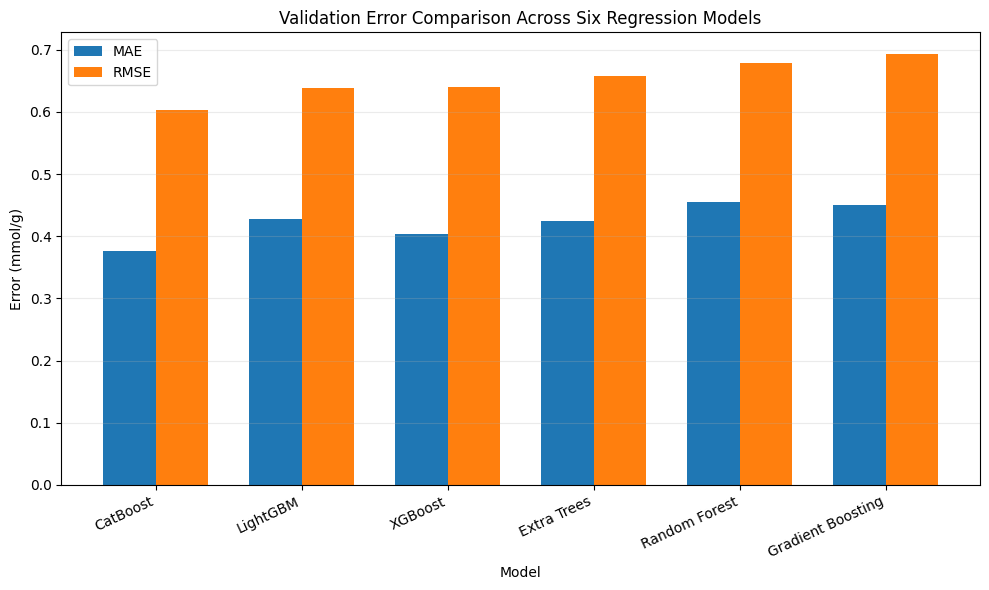

Saved: results/figures/advanced_model_error_comparison.png


In [ ]:

plot_df = comparison_df.sort_values("RMSE", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(plot_df))
width = 0.36

ax.bar(x - width / 2, plot_df["MAE"], width, label="MAE")
ax.bar(x + width / 2, plot_df["RMSE"], width, label="RMSE")

ax.set_title("Validation Error Comparison Across Six Regression Models")
ax.set_xlabel("Model")
ax.set_ylabel("Error (mmol/g)")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=25, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
error_plot_path = PLOT_DIR / "advanced_model_error_comparison.png"
fig.savefig(error_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", error_plot_path.relative_to(PROJECT_ROOT))


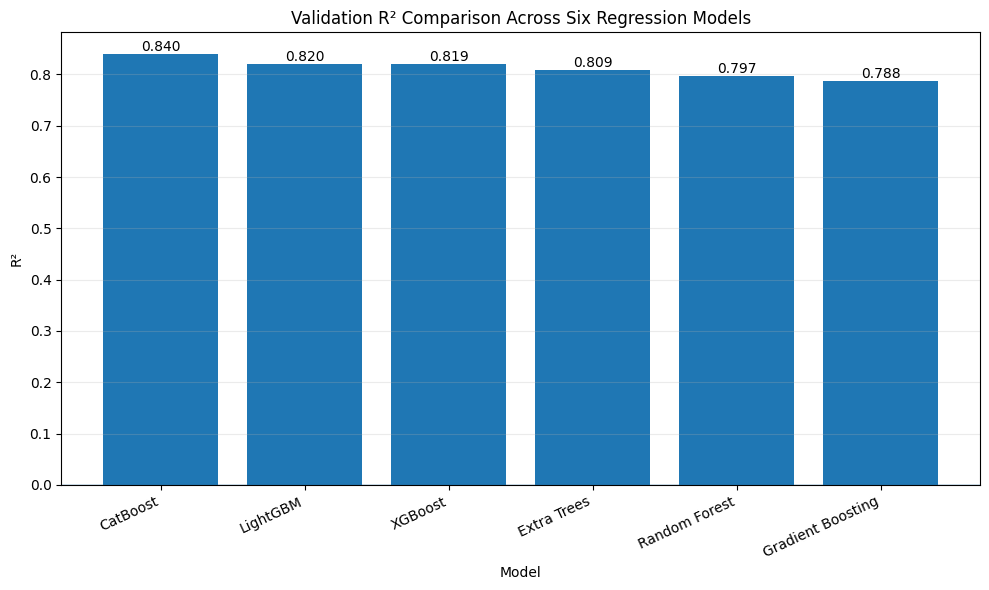

Saved: results/figures/advanced_model_r2_comparison.png


In [ ]:

r2_df = comparison_df.sort_values("R2", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(r2_df["Model"], r2_df["R2"])
ax.set_title("Validation R² Comparison Across Six Regression Models")
ax.set_xlabel("Model")
ax.set_ylabel("R²")
ax.set_xticks(range(len(r2_df)))
ax.set_xticklabels(r2_df["Model"], rotation=25, ha="right")
ax.axhline(0, linewidth=1)
ax.grid(axis="y", alpha=0.25)

# Label each bar with its R² value.
for bar, score in zip(bars, r2_df["R2"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.3f}",
        ha="center",
        va="bottom" if score >= 0 else "top",
    )

fig.tight_layout()
r2_plot_path = PLOT_DIR / "advanced_model_r2_comparison.png"
fig.savefig(r2_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", r2_plot_path.relative_to(PROJECT_ROOT))


Best initial model by validation RMSE: CatBoost
Validation MAE:  0.3766 mmol/g
Validation RMSE: 0.6024 mmol/g
Validation R²:   0.8400


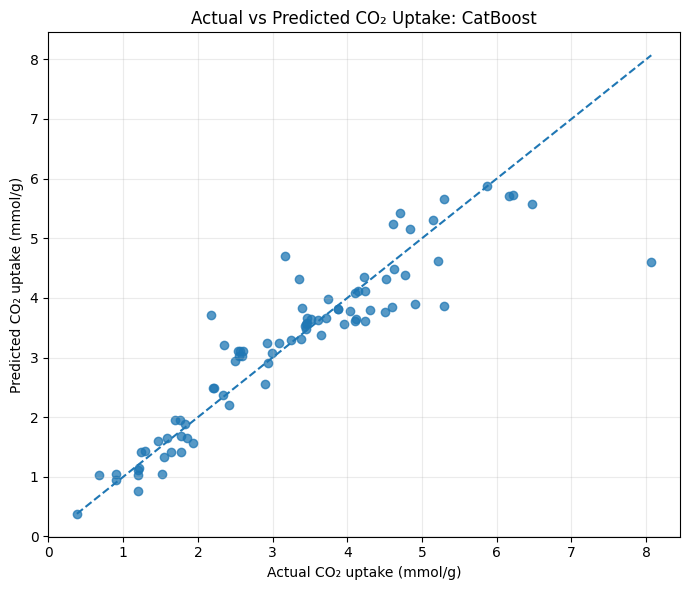

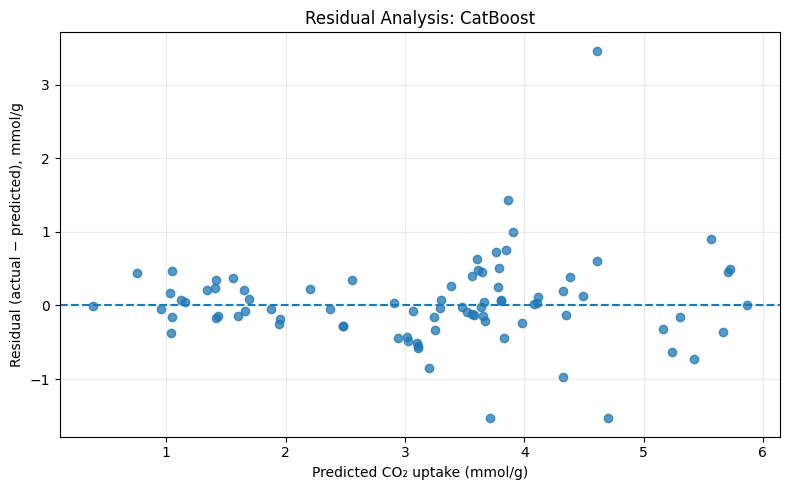

Saved: results/figures/best_initial_model_actual_vs_predicted.png
Saved: results/figures/best_initial_model_residuals.png


In [ ]:

best_model_name = comparison_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]
best_predictions = validation_predictions[best_model_name]

residuals = y_val.to_numpy() - best_predictions

print("Best initial model by validation RMSE:", best_model_name)
print(f"Validation MAE:  {mean_absolute_error(y_val, best_predictions):.4f} mmol/g")
print(f"Validation RMSE: {np.sqrt(mean_squared_error(y_val, best_predictions)):.4f} mmol/g")
print(f"Validation R²:   {r2_score(y_val, best_predictions):.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_val, best_predictions, alpha=0.75)

lower = min(float(y_val.min()), float(np.min(best_predictions)))
upper = max(float(y_val.max()), float(np.max(best_predictions)))
ax.plot([lower, upper], [lower, upper], linestyle="--")

ax.set_title(f"Actual vs Predicted CO₂ Uptake: {best_model_name}")
ax.set_xlabel("Actual CO₂ uptake (mmol/g)")
ax.set_ylabel("Predicted CO₂ uptake (mmol/g)")
ax.grid(alpha=0.25)

fig.tight_layout()
actual_predicted_path = PLOT_DIR / "best_initial_model_actual_vs_predicted.png"
fig.savefig(actual_predicted_path, dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(best_predictions, residuals, alpha=0.75)
ax.axhline(0, linestyle="--")

ax.set_title(f"Residual Analysis: {best_model_name}")
ax.set_xlabel("Predicted CO₂ uptake (mmol/g)")
ax.set_ylabel("Residual (actual − predicted), mmol/g")
ax.grid(alpha=0.25)

fig.tight_layout()
residual_plot_path = PLOT_DIR / "best_initial_model_residuals.png"
fig.savefig(residual_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", actual_predicted_path.relative_to(PROJECT_ROOT))
print("Saved:", residual_plot_path.relative_to(PROJECT_ROOT))


In [ ]:

run_summary = {
    "notebook": "05_advanced_model_comparison.ipynb",
    "random_state": RANDOM_STATE,
    "dataset": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "split_file": str(SPLIT_PATH.relative_to(PROJECT_ROOT)),
    "target": TARGET_COLUMN,
    "features": FEATURE_COLUMNS,
    "training_rows": int(len(X_train)),
    "validation_rows": int(len(X_val)),
    "test_rows_reserved": int(len(test_df)),
    "models_trained": list(trained_pipelines.keys()),
    "selection_metric": "RMSE",
    "best_initial_model_by_validation_rmse": str(best_model_name),
    "best_initial_validation_rmse": float(comparison_df.iloc[0]["RMSE"]),
    "best_initial_validation_mae": float(comparison_df.iloc[0]["MAE"]),
    "best_initial_validation_r2": float(comparison_df.iloc[0]["R2"]),
    "preprocessing": "Median imputation inside each model pipeline",
    "test_set_used": False,
}

summary_path = RESULTS_DIR / "advanced_model_comparison_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(run_summary, file, indent=4, ensure_ascii=False)

print("Run summary saved:", summary_path.relative_to(PROJECT_ROOT))
print("\nNotebook 05 outputs:")
for path in [
    comparison_path,
    predictions_path,
    summary_path,
    error_plot_path,
    r2_plot_path,
    actual_predicted_path,
    residual_plot_path,
]:
    print("-", path.relative_to(PROJECT_ROOT))


Run summary saved: results/advanced_model_comparison_summary.json

Notebook 05 outputs:
- results/advanced_model_comparison.csv
- results/advanced_model_validation_predictions.csv
- results/advanced_model_comparison_summary.json
- results/figures/advanced_model_error_comparison.png
- results/figures/advanced_model_r2_comparison.png
- results/figures/best_initial_model_actual_vs_predicted.png
- results/figures/best_initial_model_residuals.png



## Conclusion

Six tree-based regression models were trained and evaluated using the same training and validation split. Median imputation was incorporated into each model's pipeline to ensure that imputation parameters were learned exclusively from the training data.

Model performance was compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). Validation predictions and diagnostic plots were generated to support further error analysis.

The model with the lowest validation RMSE was identified as the best-performing initial candidate. This result will be treated as a preliminary benchmark rather than a final model selection.

### Next Steps
1. Perform hyperparameter optimization.
2. Re-evaluate the tuned models on the validation set.
3. Construct and evaluate ensemble strategies.
4. Select the final modeling approach using validation results.
5. Evaluate the selected approach on the untouched test set.
6. Apply explainability techniques and prepare the trained model for deployment through the FastAPI application.
